In [1]:
!pip install pandas openpyxl
import pandas as pd
import numpy as np
# Load Excel file
data= pd.read_excel("C:/Users/HP/Downloads/Malaria_Data.xlsx")
print(data)

Defaulting to user installation because normal site-packages is not writeable
         Continent    Country  Year  Malaria cases  Malaria deaths  \
0    South America  Argentina  2000            440               0   
1    South America  Argentina  2001            215               0   
2    South America  Argentina  2002            125               0   
3    South America  Argentina  2003            124               1   
4    South America  Argentina  2004            116               0   
..             ...        ...   ...            ...             ...   
248  South America  Venezuela  2018         474766             373   
249  South America  Venezuela  2019         466830             350   
250  South America  Venezuela  2020         223067             196   
251  South America  Venezuela  2021         204424             155   
252  South America  Venezuela  2022         154089             125   

     Malaria incidence  Malaria mortality  Indigenous cases  P. falciparum  \
0  

In [27]:
print(data.columns.tolist())

['Continent', 'Country', 'Year', 'Malaria cases', 'Malaria deaths', 'Malaria incidence', 'Malaria mortality', 'Indigenous cases', 'P. falciparum', ' P. vivax', 'y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'y9', 'y10', 'y11', 'y12', 'y13', 'y14', 'y15', 'y16', 'y17', 'y18', 'y19', 'y20', 'y21', 'y22']


In [2]:
#poisson regression model without offset


import statsmodels.api as sm
import statsmodels.formula.api as smf
# Model 1: Poisson Regression without offset

poisson_model = smf.glm(
    formula='Q("Malaria cases")~ y1 + y2 + y5 + y6 + y9 + y10 + y16 + y17 + y18 + y19',
    data=data,family=sm.families.Poisson()
).fit()
print (poisson_model.summary())



                 Generalized Linear Model Regression Results                  
Dep. Variable:     Q("Malaria cases")   No. Observations:                  253
Model:                            GLM   Df Residuals:                      242
Model Family:                 Poisson   Df Model:                           10
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.5534e+07
Date:                Tue, 17 Nov 2026   Deviance:                   3.1066e+07
Time:                        20:29:54   Pearson chi2:                 3.78e+07
No. Iterations:                     9   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      9.8638      0.001   7770.483      0.0

In [3]:
#Calculate mean and variance of poisson model for dispersion checking


mean_cases = data["Malaria cases"].mean()
variance_cases = data["Malaria cases"].var()

print("Mean malaria cases:", mean_cases) 
print("Variance of malaria cases:", variance_cases)

if variance_cases > mean_cases: print("Potential evidence of overdispersion")
else:
    print("No indication of overdispersion based on mean and variance")

Mean malaria cases: 69350.69565217392
Variance of malaria cases: 15297170037.61732
Potential evidence of overdispersion


In [4]:
#overdispersion checking
#Pearson chi-square

pearson_chi2 = sum(poisson_model.resid_pearson**2)

#Residual degrees of freedom
residual_df = poisson_model.df_resid

# Dispersion statistic
dispersion = pearson_chi2/ residual_df

print("Pearson Chi-square:", pearson_chi2)
print("Residual degrees of freedom:", residual_df)
print("Dispersion statistic:", dispersion)

Pearson Chi-square: 37802314.07215412
Residual degrees of freedom: 242
Dispersion statistic: 156207.9093890666


In [5]:
# Fit Negative Binomial regression model without offset


nb_model = smf.glm(
    formula='Q("Malaria cases")~ y1 + y2 + y5 + y6 + y9 + y10 + y16 + y17 + y18 + y19',
    data=data,family=sm.families.NegativeBinomial()
).fit()

# Display results
print(nb_model.summary())

# Calculate Incidence Rate Ratios (IRR)
print("Incidence Rate Ratios:") 
print(np.exp(nb_model.params))

                 Generalized Linear Model Regression Results                  
Dep. Variable:     Q("Malaria cases")   No. Observations:                  253
Model:                            GLM   Df Residuals:                      242
Model Family:        NegativeBinomial   Df Model:                           10
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2990.2
Date:                Tue, 17 Nov 2026   Deviance:                       1198.7
Time:                        20:30:04   Pearson chi2:                     441.
No. Iterations:                    36   Pseudo R-squ. (CS):             0.4811
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.0268      0.198     40.470      0.0

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\genmod\families\family.py:1367: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  warnings.warn("Negative binomial dispersion parameter alpha not "


In [6]:
#Compare model performance


# Model comparison
comparison = pd. DataFrame({
    "Model": ["Poisson Regression", "Negative Binomial Regression"],
    "AIC": [poisson_model.aic, nb_model.aic],
    "Deviance": [poisson_model.deviance, nb_model.deviance],
    "Log-Likelihood": [
                poisson_model.llf,
                nb_model.llf]
})
print (comparison)

                          Model           AIC      Deviance  Log-Likelihood
0            Poisson Regression  3.106818e+07  3.106557e+07   -1.553408e+07
1  Negative Binomial Regression  6.002358e+03  1.198743e+03   -2.990179e+03


In [7]:
#excess zeros 


import numpy as np

zero_count = (data["Malaria cases"] == 0).sum()

expected_zero = np.exp(-poisson_model.predict(data)).sum()

print("Observed zeros =", zero_count)
print("Expected zeros =", expected_zero)

Observed zeros = 24
Expected zeros = 0.0


In [8]:
#excess zero 

expected = np.exp(-poisson_model.predict(data))

print("Expected zero probability =", expected.mean())
print("Expected zero count =", expected.sum())
print("Minimum predicted mean =", poisson_model.predict(data).min())

Expected zero probability = 0.0
Expected zero count = 0.0
Minimum predicted mean = 13933.525271981262


In [9]:
#Model 2: Poisson Regression with population offset


poisson_with = smf.glm(
    formula='Q("Malaria cases")~ y1 + y2 + y5 + y6 + y9 + y10 + y16 + y17 + y18 + y19',
    data=data,family=sm.families.Poisson(),
    offset=np.log(data["y7"])
).fit()
print (poisson_with.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:     Q("Malaria cases")   No. Observations:                  253
Model:                            GLM   Df Residuals:                      242
Model Family:                 Poisson   Df Model:                           10
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -6.5835e+06
Date:                Tue, 17 Nov 2026   Deviance:                   1.3165e+07
Time:                        20:30:22   Pearson chi2:                 3.29e+07
No. Iterations:                     7   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.5076      0.003  -1717.522      0.0

In [22]:
import numpy as np
import statsmodels.api as sm

# Variables
y = data["Malaria cases"]
xvars = ["y1","y2","y5","y6","y9","y10","y16","y17","y18","y19"]

df = data[["Malaria cases","y7"] + xvars].apply(
    lambda x: np.asarray(x)
)

df = data[["Malaria cases","y7"] + xvars].copy()
df = df.replace([np.inf,-np.inf],np.nan).dropna()
df = df[df["y7"] > 0]

# Standardize predictors
for x in xvars:
    df[x] = (df[x]-df[x].mean())/df[x].std()

X = sm.add_constant(df[xvars])
Y = df["Malaria cases"]
offset = np.log(df["y7"])



# Model 4: With Population Offset
p = sm.GLM(
    Y,X,family=sm.families.Poisson(),offset=offset
).fit()

negative_with = sm.NegativeBinomial(Y,X,offset=offset).fit(
    start_params=np.r_[p.params,1.0],
    method="bfgs",maxiter=5000,disp=False
)

print("\nMODEL 4: WITH POPULATION OFFSET")
print(m4.summary())


MODEL 4: WITH POPULATION OFFSET
                     NegativeBinomial Regression Results                      
Dep. Variable:          Malaria cases   No. Observations:                  253
Model:               NegativeBinomial   Df Residuals:                      242
Method:                           MLE   Df Model:                           10
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                 0.01422
Time:                        20:48:56   Log-Likelihood:                -2723.6
converged:                       True   LL-Null:                       -2762.9
Covariance Type:            nonrobust   LLR p-value:                 9.518e-13
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -5.5694      0.113    -49.230      0.000      -5.791      -5.348
y1            -0.5873      0.269     -2.180      0.029      -1.115      -0.059
y2            -0.26

In [23]:
#Compare all four models

comparison = pd. DataFrame({
    "Model": [
        "Poisson Without Offset",
        "Poisson With Offset",
        "Negative Binomial Without Offset",
        "Negative Binomial With Offse"
],

"AIC": [
    poisson_model.aic,
    poisson_with.aic,
    nb_model.aic,
    nb_with.aic
],

"Log-Likelihood": [
    poisson_model.llf,
    poisson_with.llf,
    nb_model.llf,
    nb_with.llf
]

})

print (comparison.sort_values("AIC"))

                              Model           AIC  Log-Likelihood
2  Negative Binomial Without Offset  6.002358e+03   -2.990179e+03
1               Poisson With Offset  1.316711e+07   -6.583546e+06
0            Poisson Without Offset  3.106818e+07   -1.553408e+07
3      Negative Binomial With Offse           NaN             NaN


In [14]:
#comparison of ZIP model with offset and ZINB model with offset

from sklearn.preprocessing import StandardScaler
from statsmodels.discrete.count_model import ZeroInflatedPoisson, ZeroInflatedNegativeBinomialP
import statsmodels.api as sm
import numpy as np

cols = ['Malaria cases','y1','y2','y5','y6','y9','y10','y16','y17','y18','y19','y7']

d = data[cols].copy()

d = d.replace([np.inf, -np.inf], np.nan).dropna()
d = d[(d['y7'] > 0) & (d['Malaria cases'] >= 0)]

X = StandardScaler().fit_transform(d[['y1','y2','y5','y6','y9','y10','y16','y17','y18','y19']])
X = sm.add_constant(X)

Z = np.ones((len(d), 1))

offset = np.log(d['y7'])

zip_model = ZeroInflatedPoisson(
    d['Malaria cases'], X,
    exog_infl=Z,

    offset=offset,
    inflation='logit'
).fit(method='bfgs', maxiter=500, disp=0)

zinb_model = ZeroInflatedNegativeBinomialP(
    d['Malaria cases'], X,
    exog_infl=Z,
    offset=offset,
    inflation='logit'
).fit(method='bfgs', maxiter=500, disp=0)

print("ZIP AIC =", zip_model.aic)
print("ZINB AIC =", zinb_model.aic)

print("ZIP Converged =", zip_model.mle_retvals['converged'])
print("ZINB Converged =", zinb_model.mle_retvals['converged'])

ZIP AIC = 12276954.284997875
ZINB AIC = 5473.2840645870465
ZIP Converged = True
ZINB Converged = True


C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\discrete\count_model.py:629: RuntimeWarning: overflow encountered in exp
  coeff = (1 + w[zero_idx] * (np.exp(mu[zero_idx]) - 1))
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\discrete\count_model.py:637: RuntimeWarning: overflow encountered in exp
  w[zero_idx] * mu[zero_idx] * np.exp(mu[zero_idx]) /
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\discrete\count_model.py:637: RuntimeWarning: invalid value encountered in divide
  w[zero_idx] * mu[zero_idx] * np.exp(mu[zero_idx]) /
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '
C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '

In [15]:
pearson_chi2 = sum(zip_model.resid_pearson**2)

#Residual degrees of freedom
residual_df = zip_model.df_resid

# Dispersion statistic
dispersion = pearson_chi2/ residual_df

print("Pearson Chi-square:", pearson_chi2)
print("Residual degrees of freedom:", residual_df)
print("Dispersion statistic:", dispersion)

Pearson Chi-square: 294139.2833346642
Residual degrees of freedom: 242.0
Dispersion statistic: 1215.451584027538


In [16]:
pearson_chi2 = sum(zinb_model.resid_pearson**2)

#Residual degrees of freedom
residual_df = zinb_model.df_resid

# Dispersion statistic
dispersion = pearson_chi2/ residual_df

print("Pearson Chi-square:", pearson_chi2)
print("Residual degrees of freedom:", residual_df)
print("Dispersion statistic:", dispersion)

Pearson Chi-square: 158.3833958477032
Residual degrees of freedom: 242.0
Dispersion statistic: 0.654476842345881


In [17]:
##IRR for these two model
import numpy as np

print("ZIP IRR:")
print(np.exp(zip_model.params[:X.shape[0]]))

print("ZINB IRR:")
print(np.exp(zinb_model.params[:X.shape[0]]))

ZIP IRR:
inflate_const    0.104803
const            0.002167
x1               1.114100
x2               0.810526
x3               0.645265
x4               1.149461
x5               1.643164
x6               0.974596
x7               1.046362
x8               0.732106
x9               1.222260
x10              1.235683
dtype: float64
ZINB IRR:
inflate_const    5.352124e-61
const            3.812981e-03
x1               5.564839e-01
x2               7.671042e-01
x3               6.441333e-01
x4               5.877229e-01
x5               8.159584e-01
x6               9.008427e-01
x7               1.140374e+00
x8               8.893619e-01
x9               1.293825e+00
x10              3.506248e+00
alpha            2.547725e+01
dtype: float64


In [18]:
#Generate predicted malaria cases with offset model
data["ZIP Predicted"] = zip_model.predict()
data["ZINB Predicted"] = zinb_model.predict()

print(data[["Malaria cases", "ZIP Predicted", "ZINB Predicted"]].head())

   Malaria cases  ZIP Predicted  ZINB Predicted
0            440   18332.936501    54549.066970
1            215   43255.375774   104673.379117
2            125   39651.664945    93556.196796
3            124   45021.854224   104093.285481
4            116   48917.806312   109806.014485


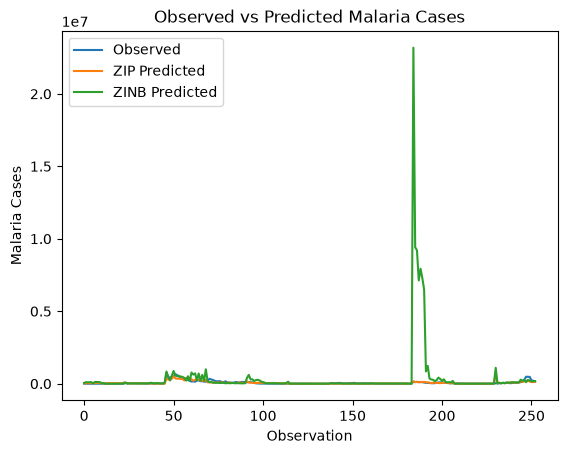

In [46]:
#Visualize observed versus predicted dengue cases
import matplotlib.pyplot as plt

plt.plot(data["Malaria cases"], label="Observed")
plt.plot(zip_model.predict(), label="ZIP Predicted")
plt.plot(zinb_model.predict(), label="ZINB Predicted")

plt.xlabel("Observation")
plt.ylabel("Malaria Cases")
plt.legend()
plt.title("Observed vs Predicted Malaria Cases")
plt.show()

In [47]:
# final model selection 
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y = data["Malaria cases"]

for name, pred in [("ZIP", zip_model.predict()),
                   ("ZINB", zinb_model.predict())]:
    print(name, "MAE =", mean_absolute_error(y, pred))
    print(name, "RMSE =", np.sqrt(mean_squared_error(y, pred)))

ZIP MAE = 41019.974658945786
ZIP RMSE = 81517.74098797563
ZINB MAE = 351725.4458024946
ZINB RMSE = 1896928.925105151


C:\ProgramData\anaconda3\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Malaria Cases Forecast (2023-2032):
Year
2023    1125.180718
2024    1147.684333
2025    1170.638019
2026    1194.050780
2027    1217.931795
2028    1242.290431
2029    1267.136240
2030    1292.478965
2031    1318.328544
2032    1344.695115
Name: Predicted_Malaria, dtype: float64


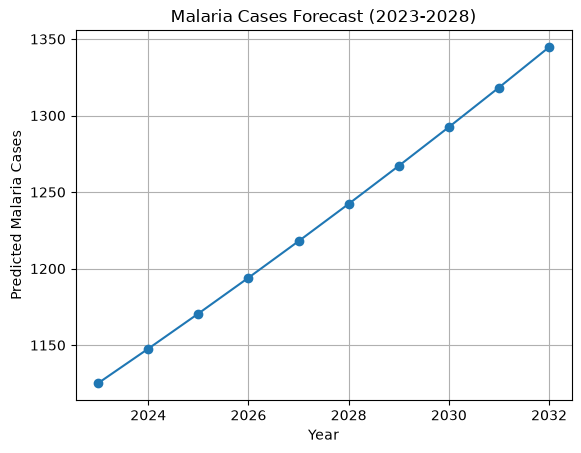

In [51]:
#forecating
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Independent variables
variables = ['y1','y2','y5','y6','y9','y10',
             'y16','y17','y18','y19']

# Future data (2023-2028)
last = data.groupby('Country').tail(1).copy()
future_list = []

for year in range(2023, 2033):
    temp = last.copy()
    temp['Year'] = year

    for v in variables:
        temp[v] = temp[v]  # Latest values ধরে রাখা

    temp['y7'] = temp['y7'] * (1.02 ** (year - data['Year'].max()))
    future_list.append(temp)

future = pd.concat(future_list, ignore_index=True)

# Prediction using fitted ZINB model
X_future = sm.add_constant(future[variables], has_constant='add')
Z_future = np.ones((len(future), 1))

future['Predicted_Malaria'] = zinb_model.predict(
    exog=X_future,
    exog_infl=Z_future,
    offset=np.log(future['y7']),
    which='mean'
)

# Total predicted cases by year
forecast = future.groupby('Year')['Predicted_Malaria'].sum()

print("Malaria Cases Forecast (2023-2032):")
print(forecast)

# Forecast plot
forecast.plot(marker='o')
plt.title('Malaria Cases Forecast (2023-2028)')
plt.xlabel('Year')
plt.ylabel('Predicted Malaria Cases')
plt.grid()
plt.show()

Malaria Cases Forecast (2023-2032):
Year
2023    48700.073571
2024    49674.075042
2025    50667.556543
2026    51680.907674
2027    52714.525827
2028    53768.816344
2029    54844.192671
2030    55941.076524
2031    57059.898055
2032    58201.096016
Name: Predicted_Malaria, dtype: float64


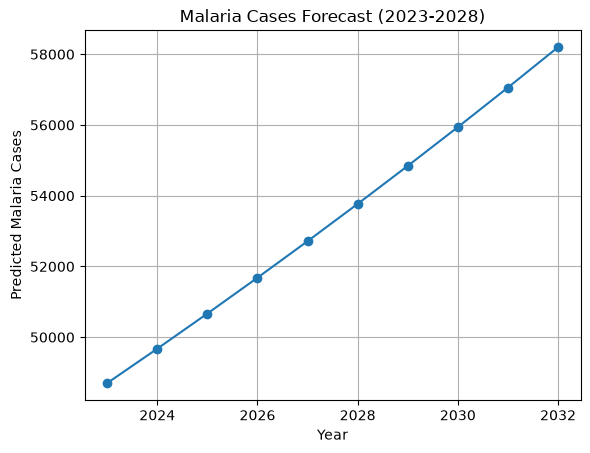

In [30]:
#forecating
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Independent variables
variables = ['y1','y2','y5','y6','y9','y10',
             'y16','y17','y18','y19']

# Future data (2023-2028)
last = data.groupby('Country').tail(1).copy()
future_list = []

for year in range(2023, 2033):
    temp = last.copy()
    temp['Year'] = year

    for v in variables:
        temp[v] = temp[v]  # Latest values ধরে রাখা

    temp['y7'] = temp['y7'] * (1.02 ** (year - data['Year'].max()))
    future_list.append(temp)

future = pd.concat(future_list, ignore_index=True)

# Prediction using fitted ZINB model
X_future = sm.add_constant(future[variables], has_constant='add')
Z_future = np.ones((len(future), 1))

future['Predicted_Malaria'] = zip_model.predict(
    exog=X_future,
    exog_infl=Z_future,
    offset=np.log(future['y7']),
    which='mean'
)

# Total predicted cases by year
forecast = future.groupby('Year')['Predicted_Malaria'].sum()

print("Malaria Cases Forecast (2023-2032):")
print(forecast)

# Forecast plot
forecast.plot(marker='o')
plt.title('Malaria Cases Forecast (2023-2028)')
plt.xlabel('Year')
plt.ylabel('Predicted Malaria Cases')
plt.grid()
plt.show()